# 03 — ML de series de tiempo: humedad radicular SMAP a 7 días

Este notebook prueba si un modelo ML con memoria temporal y estacionalidad pronostica mejor la humedad radicular SMAP que reglas simples. El objetivo medible es SMAP root-zone a siete días, no el rendimiento del cultivo: por ahora no tenemos rendimientos de parcela Ames enlazados con rotaciones y manejo para entrenar o validar una corrección de WOFOST.

Se compara persistencia, climatología por mes calculada solo con el pasado y HistGradientBoosting con variables de humedad/clima recientes y seno/coseno del día objetivo. Se usa validación de origen móvil por años (2020–2025), nunca una partición aleatoria. En cada fecha de prueba se supone que ya se conocen SMAP y POWER hasta esa fecha; por eso es una evaluación rodante diaria, no un pronóstico hecho una sola vez para todo el año.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'data_corn_belt').is_dir())
DATA = ROOT / 'src' / 'data_corn_belt'
DAILY_PATH = DATA / 'corn_belt_daily_2015_2025.csv'
daily = pd.read_csv(DAILY_PATH, parse_dates=['date']).set_index('date').sort_index()
daily.index.name = 'date_utc'
print('Filas:', len(daily), '| periodo:', daily.index.min().date(), '→', daily.index.max().date())
display(pd.DataFrame({'faltantes': daily[['PRECTOTCORR', 'T2M', 'smap_sm_surface', 'smap_sm_rootzone']].isna().sum()}))

Filas: 3929 | periodo: 2015-03-31 → 2025-12-31


,faltantes
PRECTOTCORR,0
T2M,0
smap_sm_surface,0
smap_sm_rootzone,0


## 1. Revisar la estacionalidad del objetivo

SMAP L4 entrega ocho muestras de tres horas al día en el CSV fuente; la tabla diaria ya las resume con una media. La serie es una estimación de humedad de 0–100 cm y no una medición directa de una parcela. El ciclo mensual y la variabilidad interanual justifican comparar explícitamente contra una referencia estacional.

,rootzone_mean,rootzone_std,precipitation_daily_mean
date_utc,,,
1,0.285,0.039,0.971
2,0.297,0.037,0.868
3,0.314,0.034,1.848
4,0.318,0.022,2.133
5,0.324,0.023,3.585
6,0.314,0.028,3.856
7,0.292,0.035,3.332
8,0.259,0.034,3.164
9,0.250,0.035,2.693


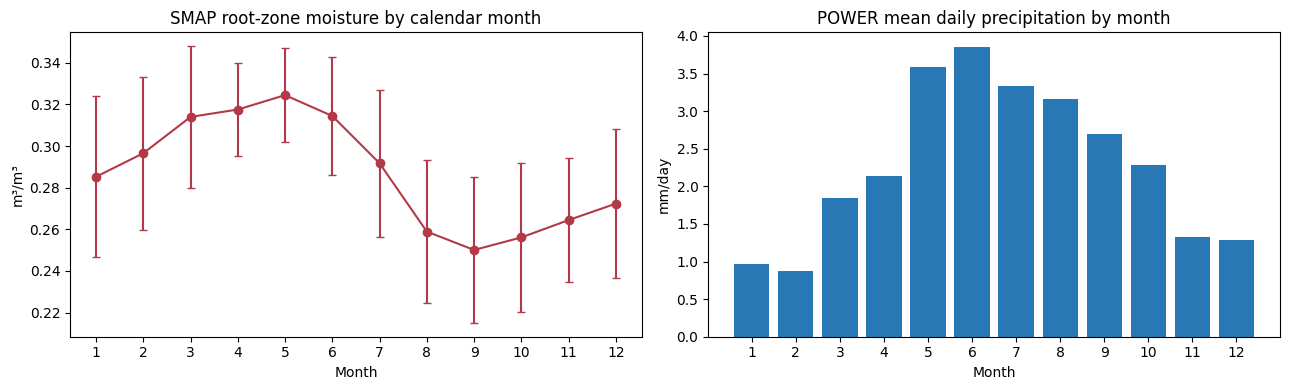

In [2]:
monthly_climatology = daily.groupby(daily.index.month).agg(
    rootzone_mean=('smap_sm_rootzone', 'mean'),
    rootzone_std=('smap_sm_rootzone', 'std'),
    precipitation_daily_mean=('PRECTOTCORR', 'mean'),
).reindex(range(1, 13))
display(monthly_climatology.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(monthly_climatology.index, monthly_climatology['rootzone_mean'], yerr=monthly_climatology['rootzone_std'], marker='o', capsize=3, color='#B23A48')
axes[0].set(title='SMAP root-zone moisture by calendar month', xlabel='Month', ylabel='m³/m³', xticks=range(1, 13))
axes[1].bar(monthly_climatology.index, monthly_climatology['precipitation_daily_mean'], color='#2878B5')
axes[1].set(title='POWER mean daily precipitation by month', xlabel='Month', ylabel='mm/day', xticks=range(1, 13))
plt.tight_layout()

## 2. Construcción del problema supervisado

Cada fila representa una fecha de emisión. El objetivo es la humedad SMAP siete días después. Los predictores se limitan a información disponible en la fecha de emisión: humedad actual y rezagos, lluvia acumulada hasta esa fecha, temperatura reciente y fase estacional conocida de la fecha objetivo. No se usan lluvia o temperatura futuras, ni columnas estáticas de suelo repetidas como si fueran observaciones independientes.

In [3]:
HORIZON_DAYS = 7
rootzone = daily['smap_sm_rootzone'].astype(float)
rain = daily['PRECTOTCORR'].astype(float)
temperature = daily['T2M'].astype(float)
surface = daily['smap_sm_surface'].astype(float)

X = pd.DataFrame(index=daily.index)
X['rootzone_now'] = rootzone
for lag in [1, 3, 7, 14, 30]:
    X[f'rootzone_lag_{lag}d'] = rootzone.shift(lag)
X['surface_now'] = surface
X['rain_sum_7d'] = rain.rolling(7, min_periods=7).sum()
X['rain_sum_30d'] = rain.rolling(30, min_periods=30).sum()
X['temperature_mean_7d'] = temperature.rolling(7, min_periods=7).mean()
X['temperature_mean_30d'] = temperature.rolling(30, min_periods=30).mean()

forecast_dates = pd.Series(daily.index + pd.Timedelta(days=HORIZON_DAYS), index=daily.index)
days_in_year = np.where(forecast_dates.dt.is_leap_year, 366.0, 365.0)
phase = 2 * np.pi * (forecast_dates.dt.dayofyear.to_numpy() - 1) / days_in_year
X['target_doy_sin'] = np.sin(phase)
X['target_doy_cos'] = np.cos(phase)

supervised = X.copy()
supervised['target'] = rootzone.shift(-HORIZON_DAYS)
supervised['target_date'] = forecast_dates
supervised['target_month'] = supervised['target_date'].dt.month
FEATURES = list(X.columns)
supervised = supervised.dropna(subset=FEATURES + ['target']).copy()
print('Horizon:', HORIZON_DAYS, 'days | filas supervisadas:', len(supervised), '| predictores:', len(FEATURES))
display(supervised[FEATURES + ['target', 'target_date']].head())

Horizon: 7 days | filas supervisadas: 3892 | predictores: 13


,rootzone_now,rootzone_lag_1d,rootzone_lag_3d,rootzone_lag_7d,rootzone_lag_14d,rootzone_lag_30d,surface_now,rain_sum_7d,rain_sum_30d,temperature_mean_7d,temperature_mean_30d,target_doy_sin,target_doy_cos,target,target_date
date_utc,,,,,,,,,,,,,,,
2015-04-30,0.310173,0.313232,0.317557,0.316657,0.308041,0.311001,0.233514,14.46,79.22,11.632857,10.904667,0.826354,-0.563151,0.317884,2015-05-07
2015-05-01,0.307915,0.310173,0.315798,0.315437,0.306055,0.310246,0.226662,12.73,79.51,11.932857,10.815667,0.816538,-0.577292,0.316719,2015-05-08
2015-05-02,0.307656,0.307915,0.313232,0.320141,0.307458,0.313552,0.245553,3.21,69.98,12.798571,10.858333,0.806480,-0.591261,0.313771,2015-05-09
2015-05-03,0.306118,0.307656,0.310173,0.320614,0.321398,0.314315,0.256229,3.55,69.99,14.187143,11.288667,0.796183,-0.605056,0.311034,2015-05-10
2015-05-04,0.310970,0.306118,0.307915,0.317557,0.326552,0.312945,0.315574,12.04,78.48,15.198571,11.689333,0.785650,-0.618671,0.315901,2015-05-11


## 3. Backtest temporal de origen móvil

Para cada año de prueba, el entrenamiento contiene únicamente objetivos fechados antes del 1 de enero de ese año. Los tres métodos se evalúan sobre las mismas fechas: persistencia (humedad actual), climatología mensual calculada con objetivos de entrenamiento y ML. El estimador y sus hiperparámetros se fijan de antemano; no se ajustan mirando los años de prueba. La climatología estacional de esta sección se recalcula dentro de cada pliegue para evitar fuga temporal.

In [4]:
TEST_YEARS = range(2020, int(supervised['target_date'].dt.year.max()) + 1)
fold_predictions = []

for test_year in TEST_YEARS:
    year_start = pd.Timestamp(f'{test_year}-01-01')
    next_year = pd.Timestamp(f'{test_year + 1}-01-01')
    train = supervised.loc[supervised['target_date'] < year_start]
    test = supervised.loc[(supervised['target_date'] >= year_start) & (supervised['target_date'] < next_year)]
    if train.empty or test.empty:
        continue

    model = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )
    model.fit(train[FEATURES], train['target'])
    monthly_means = train.groupby('target_month')['target'].mean()

    fold = pd.DataFrame(index=test.index)
    fold['target_date'] = test['target_date']
    fold['forecast_year'] = test_year
    fold['observed'] = test['target']
    fold['persistence'] = test['rootzone_now']
    fold['seasonal_month_mean'] = test['target_month'].map(monthly_means)
    fold['ml_hist_gradient_boosting'] = np.clip(model.predict(test[FEATURES]), 0.0, 1.0)
    fold_predictions.append(fold)

predictions = pd.concat(fold_predictions).sort_values('target_date')
print('Años evaluados:', sorted(predictions['forecast_year'].unique()))
print('Pronósticos de prueba:', len(predictions))
display(predictions.head())

Años evaluados: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Pronósticos de prueba: 2192


,target_date,forecast_year,observed,persistence,seasonal_month_mean,ml_hist_gradient_boosting
date_utc,,,,,,
2019-12-25,2020-01-01,2020,0.317607,0.305708,0.313334,0.315157
2019-12-26,2020-01-02,2020,0.318368,0.305662,0.313334,0.315157
2019-12-27,2020-01-03,2020,0.319528,0.305206,0.313334,0.314525
2019-12-28,2020-01-04,2020,0.319213,0.306879,0.313334,0.320366
2019-12-29,2020-01-05,2020,0.319537,0.326149,0.313334,0.325680


## 4. ¿Mejora ML frente a las referencias?

MAE y RMSE están en m³/m³; R² es complementario y puede ser sensible a la variación de cada año. La comparación decisiva es si ML reduce error frente a persistencia y climatología estacional de manera consistente entre años, no solo en el promedio agregado.

modelo,Climatología mensual,HistGradientBoosting,Persistencia
año,,,
2020,0.0319,0.0128,0.0122
2021,0.0522,0.0141,0.0109
2022,0.0388,0.0124,0.0125
2023,0.0356,0.0144,0.0136
2024,0.0366,0.0143,0.0144
2025,0.0264,0.0146,0.0138


,MAE,RMSE,R²,RMSE medio entre años
modelo,,,,
Persistencia,0.0092,0.0129,0.8908,0.0129
Climatología mensual,0.0317,0.0378,0.0699,0.0369
HistGradientBoosting,0.0104,0.0138,0.8761,0.0138


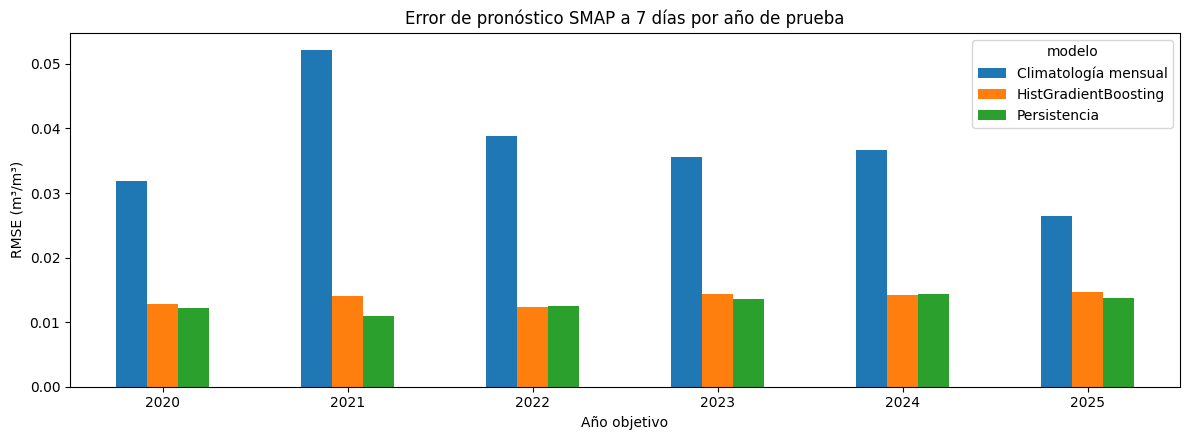

In [5]:
MODEL_COLUMNS = {
    'Persistencia': 'persistence',
    'Climatología mensual': 'seasonal_month_mean',
    'HistGradientBoosting': 'ml_hist_gradient_boosting',
}
metric_rows = []
for year, group in predictions.groupby('forecast_year'):
    for label, column in MODEL_COLUMNS.items():
        metric_rows.append({
            'año': year,
            'modelo': label,
            'n': len(group),
            'MAE': mean_absolute_error(group['observed'], group[column]),
            'RMSE': np.sqrt(mean_squared_error(group['observed'], group[column])),
            'R²': r2_score(group['observed'], group[column]),
        })
metrics_by_year = pd.DataFrame(metric_rows)
display(metrics_by_year.pivot(index='año', columns='modelo', values='RMSE').round(4))
overall_rows = []
for label, column in MODEL_COLUMNS.items():
    overall_rows.append({
        'modelo': label,
        'MAE': mean_absolute_error(predictions['observed'], predictions[column]),
        'RMSE': np.sqrt(mean_squared_error(predictions['observed'], predictions[column])),
        'R²': r2_score(predictions['observed'], predictions[column]),
        'RMSE medio entre años': metrics_by_year.loc[metrics_by_year['modelo'] == label, 'RMSE'].mean(),
    })
overall_metrics = pd.DataFrame(overall_rows).set_index('modelo')
display(overall_metrics.round(4))
ax = metrics_by_year.pivot(index='año', columns='modelo', values='RMSE').plot(kind='bar', figsize=(12, 4.5))
ax.set(title='Error de pronóstico SMAP a 7 días por año de prueba', ylabel='RMSE (m³/m³)', xlabel='Año objetivo')
plt.xticks(rotation=0)
plt.tight_layout()

## 5. Inspección del último año de prueba y error estacional

La primera gráfica muestra medias móviles de 14 días para que la comparación no quede dominada por ruido diario. La segunda desglosa MAE por mes: sirve para detectar si el método falla sistemáticamente en temporadas húmedas o secas. Ninguna de estas métricas valida el rendimiento de maíz.

modelo,Climatología mensual,HistGradientBoosting,Persistencia
mes,,,
1,0.0377,0.0040,0.0027
2,0.0360,0.0055,0.0045
3,0.0315,0.0073,0.0081
4,0.0229,0.0110,0.0101
5,0.0226,0.0169,0.0159
6,0.0227,0.0141,0.0144
7,0.0331,0.0153,0.0151
8,0.0359,0.0108,0.0131
9,0.0311,0.0126,0.0089


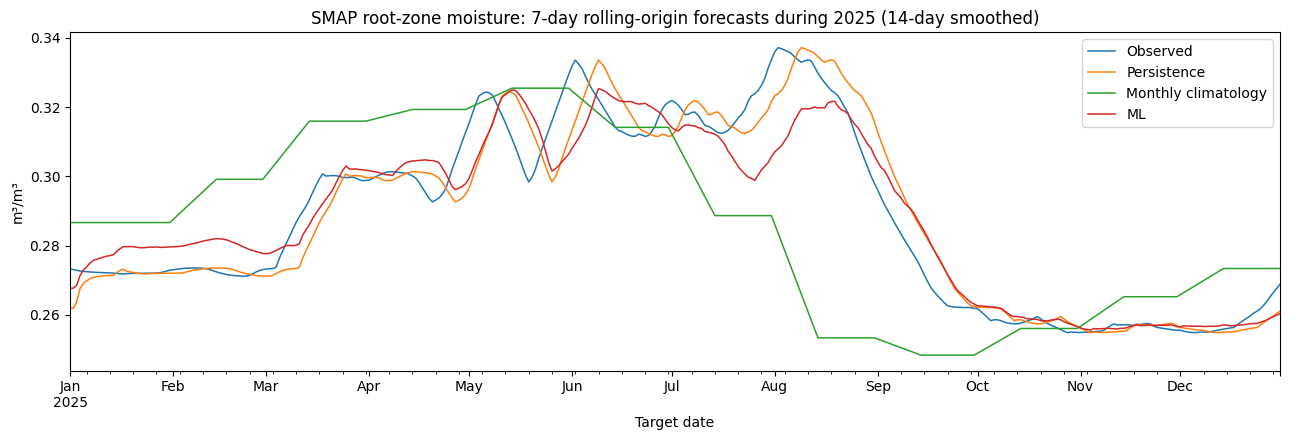

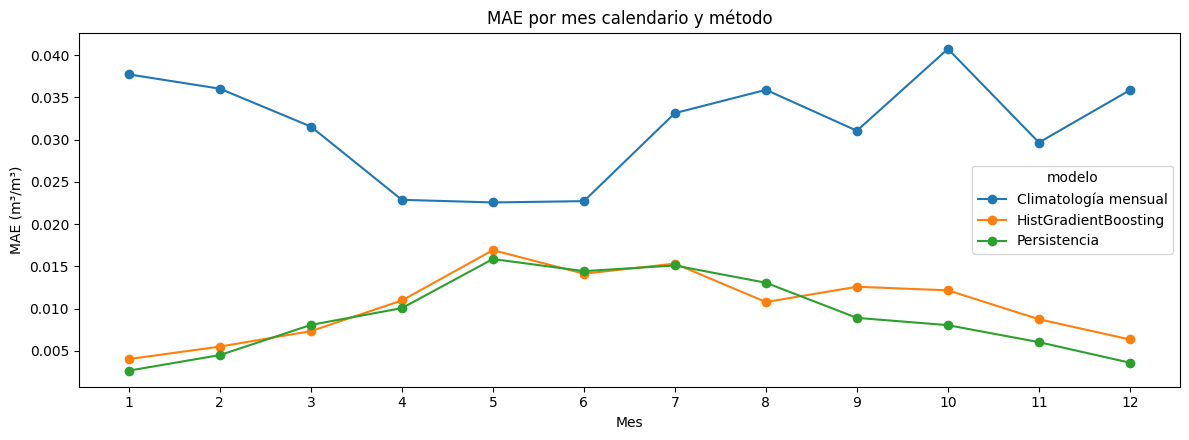

In [6]:
latest_year = int(predictions['forecast_year'].max())
latest = predictions.loc[predictions['forecast_year'] == latest_year].set_index('target_date').sort_index()
latest[['observed', 'persistence', 'seasonal_month_mean', 'ml_hist_gradient_boosting']].rolling('14D', min_periods=1).mean().plot(figsize=(13, 4.5), linewidth=1.1)
plt.title(f'SMAP root-zone moisture: 7-day rolling-origin forecasts during {latest_year} (14-day smoothed)')
plt.ylabel('m³/m³')
plt.xlabel('Target date')
plt.legend(['Observed', 'Persistence', 'Monthly climatology', 'ML'])
plt.tight_layout()

predictions['target_month'] = predictions['target_date'].dt.month
monthly_error_rows = []
for month, group in predictions.groupby('target_month'):
    for label, column in MODEL_COLUMNS.items():
        monthly_error_rows.append({'mes': month, 'modelo': label, 'MAE': mean_absolute_error(group['observed'], group[column])})
monthly_errors = pd.DataFrame(monthly_error_rows)
display(monthly_errors.pivot(index='mes', columns='modelo', values='MAE').round(4))
ax = monthly_errors.pivot(index='mes', columns='modelo', values='MAE').plot(marker='o', figsize=(12, 4.5))
ax.set(title='MAE por mes calendario y método', ylabel='MAE (m³/m³)', xlabel='Mes')
plt.xticks(range(1, 13))
plt.tight_layout()

## Interpretación y conexión con WOFOST

Este experimento solo puede considerarse una mejora si ML supera a las referencias temporales y mantiene el desempeño en los distintos años y meses de prueba. Si no lo hace, persistencia/climatología son mejores opciones por ahora. El pronóstico estima SMAP L4, que es un producto asimilado/modelado, no humedad medida en parcela.

La salida puede servir como señal de riesgo hídrico de corto plazo o como evaluación auxiliar de la dinámica de agua, pero no debe insertarse automáticamente como una observación futura dentro de WOFOST. Para corregir rendimientos WOFOST con ML necesitamos etiquetas de rendimiento locales y comparables, manejo/rotación y validación temporal/espacial independiente. Las 21 temporadas de clima y un punto de Ames no bastan para afirmar generalización regional. Para horizontes de cosecha también se necesitarían pronósticos o escenarios meteorológicos futuros, no solo clima observado hasta la fecha de emisión.